Cybersecurity Vulnerability Score Prediction

In [3]:
import pandas as pd 
import numpy as np 
import seaborn as sns

In [4]:
df = pd.read_csv("C:/Users/Varun Rajan K/Documents/ml project data sets/CyberVulnerability.csv")

In [4]:
df.shape

(100500, 50)

In [5]:
df.head()

,Incident_ID,Timestamp,Industry,Country,Company_Size,Employee_Count,Attack_Vector,Threat_Actor,Firewall,MFA,...,Month,Business_Hours,Weekend,Zero_Day,Compliance,Vendor_Count,ThirdParty_Risk,Insider_Risk,Security_Maturity,SOC_Team_Size
0,78303,2025-03-26 15:30:00,Government,Canada,Small,193,Cloud,Script Kiddie,1,0,...,March,1,0,0,NIST,7,12.2,59.9,60,3
1,66465,2024-11-23 08:00:00,Retail,UK,Small,218,Web,Nation State,1,1,...,November,0,1,1,NaN,4,50.2,53.6,80,3
2,93228,2025-08-29 02:45:00,Education,Australia,Small,33,Cloud,Cyber Criminal,1,1,...,August,0,0,0,NaN,2,23.4,12.7,100,3
3,1748,2023-01-19 04:45:00,Healthcare,Germany,Small,84,RDP,Nation State,1,0,...,January,0,0,0,HIPAA,3,25.0,1.9,80,4
4,80005,2025-04-13 09:00:00,Education,UK,Medium,305,VPN,Insider,1,0,...,April,1,1,0,NaN,6,20.2,52.1,40,3


In [6]:
df.drop(["Incident_ID","Timestamp"],axis = 1 ,inplace = True)

In [7]:
df.shape

(100500, 48)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 48 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Industry              100500 non-null  object 
 1   Country               100500 non-null  object 
 2   Company_Size          100500 non-null  object 
 3   Employee_Count        100500 non-null  int64  
 4   Attack_Vector         100500 non-null  object 
 5   Threat_Actor          100500 non-null  object 
 6   Firewall              100500 non-null  int64  
 7   MFA                   100500 non-null  int64  
 8   EDR                   100500 non-null  int64  
 9   IDS                   100500 non-null  int64  
 10  Security_Training     100500 non-null  int64  
 11  Password_Policy       100500 non-null  object 
 12  Patch_Age_Days        100500 non-null  int64  
 13  Open_Vulnerabilities  100500 non-null  int64  
 14  CVSS_Score            100500 non-null  float64
 15  

In [11]:
df.isnull().sum()

Industry                    0
Country                     0
Company_Size                0
Employee_Count              0
Attack_Vector               0
Threat_Actor                0
Firewall                    0
MFA                         0
EDR                         0
IDS                         0
Security_Training           0
Password_Policy             0
Patch_Age_Days              0
Open_Vulnerabilities        0
CVSS_Score                  0
Internet_Exposed            0
Security_Audit_Score        0
Phishing_Click              0
Credential_Stolen           0
Privilege_Escalation        0
Lateral_Movement            0
Persistence                 0
Data_Encrypted              0
Data_Exfiltration_GB        0
Attack_Success              0
Attack_Stage                0
Attack_Complexity           0
Detection_Time_Min       3166
Response_Time_Min           0
Downtime_Hours              0
Records_Compromised         0
Financial_Loss_USD       5029
Recovery_Cost_USD       70957
Cyber_Risk

In [15]:
df.drop("Recovery_Cost_USD",axis = 1 , inplace = True)   # Here null values is so high above 50% so thats why we drop the column

In [16]:
df = df.drop_duplicates() 
df.shape

(100000, 47)

<Axes: xlabel='Cyber_Risk_Score', ylabel='Financial_Loss_USD'>

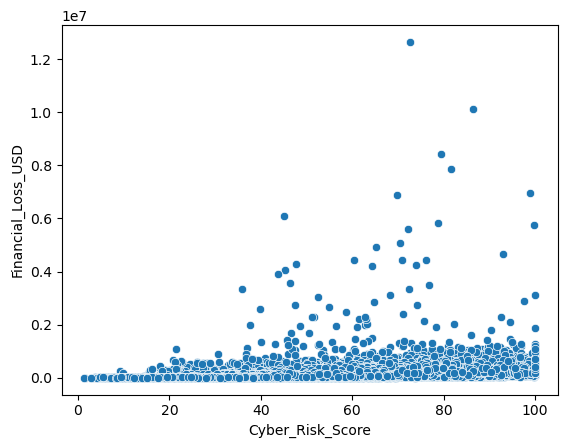

In [14]:
sns.scatterplot(x = "Cyber_Risk_Score",y = "Financial_Loss_USD",data = df)

<Axes: xlabel='Cyber_Risk_Score', ylabel='Detection_Time_Min'>

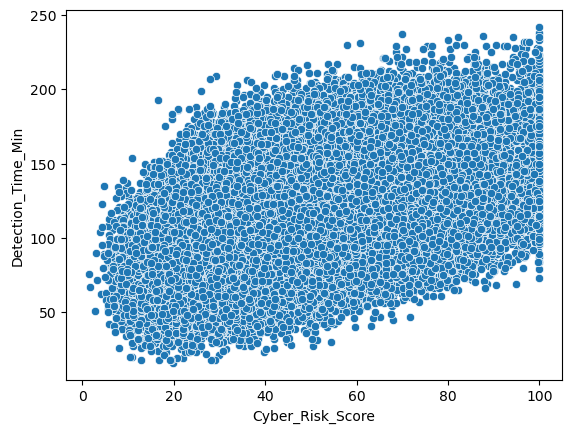

In [17]:
sns.scatterplot(x = "Cyber_Risk_Score",y = "Detection_Time_Min",data = df)

In [17]:
df["Detection_Time_Min"] = df["Detection_Time_Min"].fillna(df["Detection_Time_Min"].median())  #Filling Null values using median
df["Financial_Loss_USD"] = df["Financial_Loss_USD"].fillna(df["Financial_Loss_USD"].median())

df["Compliance"] = df["Compliance"].fillna(df["Compliance"].mode()[0])    # using mode to fill object values

In [18]:
#column separation

cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()

binary_cols = []
continuous_cols = []

for col in df.select_dtypes(include=['int64','float64']).columns:
    
    if df[col].nunique() == 2:
        binary_cols.append(col)
        
    elif df[col].nunique() > 10:
        continuous_cols.append(col)

print("Categorical Columns:")
print(cat_cols)

print("\nBinary Columns:")
print(binary_cols)

print("\nContinuous Columns:")
print(continuous_cols)

Categorical Columns:
['Industry', 'Country', 'Company_Size', 'Attack_Vector', 'Threat_Actor', 'Password_Policy', 'Attack_Stage', 'Attack_Complexity', 'Risk_Level', 'Incident_Severity', 'DayOfWeek', 'Month', 'Compliance']

Binary Columns:
['Firewall', 'MFA', 'EDR', 'IDS', 'Security_Training', 'Internet_Exposed', 'Phishing_Click', 'Credential_Stolen', 'Privilege_Escalation', 'Lateral_Movement', 'Persistence', 'Data_Encrypted', 'Attack_Success', 'Business_Hours', 'Weekend', 'Zero_Day']

Continuous Columns:
['Employee_Count', 'Patch_Age_Days', 'Open_Vulnerabilities', 'CVSS_Score', 'Security_Audit_Score', 'Data_Exfiltration_GB', 'Detection_Time_Min', 'Response_Time_Min', 'Downtime_Hours', 'Records_Compromised', 'Financial_Loss_USD', 'Cyber_Risk_Score', 'Hour', 'Vendor_Count', 'ThirdParty_Risk', 'Insider_Risk', 'SOC_Team_Size']


In [19]:
# anovaa test
from scipy.stats import f_oneway

cat_cols = df.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    groups = [g['Cyber_Risk_Score'].values
              for _, g in df[[col, 'Cyber_Risk_Score']].dropna().groupby(col)]

    if len(groups) > 1 and any(len(g) > 1 for g in groups):

        _, p_value = f_oneway(*groups)

        print(col, "->", p_value)
        print(p_value < 0.05)

    else:
        print(col, "-> nan")
        print(False)
df["Compliance"] = df["Compliance"].fillna(df["Compliance"].mode()[0])    # using mode to fill object values

Industry -> 0.0
True
Country -> 0.48486305079586434
False
Company_Size -> 0.4980768916149022
False
Attack_Vector -> 4.588338097968961e-94
True
Threat_Actor -> 0.0
True
Password_Policy -> 1.0111958557786097e-21
True
Attack_Stage -> 0.0
True
Attack_Complexity -> 3.346737937018473e-287
True
Risk_Level -> 0.0
True
Incident_Severity -> 0.0
True
DayOfWeek -> 0.5648690066181598
False
Month -> 0.856267634422717
False
Compliance -> 0.0
True


In [20]:
df.corr(numeric_only=True)["Cyber_Risk_Score"].sort_values(ascending=False)


Cyber_Risk_Score        1.000000
Attack_Success          0.717195
Downtime_Hours          0.687111
Lateral_Movement        0.573833
CVSS_Score              0.551410
Open_Vulnerabilities    0.550567
Persistence             0.548833
Data_Encrypted          0.541353
Privilege_Escalation    0.527692
Detection_Time_Min      0.506432
Financial_Loss_USD      0.460488
Data_Exfiltration_GB    0.374361
Response_Time_Min       0.297623
Patch_Age_Days          0.290920
Credential_Stolen       0.290463
Phishing_Click          0.137448
Records_Compromised     0.131055
Zero_Day                0.053994
Insider_Risk            0.019283
Hour                    0.002690
Business_Hours          0.002227
Vendor_Count            0.002212
ThirdParty_Risk         0.002200
Internet_Exposed        0.001649
Employee_Count          0.001488
SOC_Team_Size           0.001217
Weekend                -0.004111
Security_Training      -0.021676
IDS                    -0.036077
Firewall               -0.146703
EDR       

In [21]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()          # encoding all object column to train and test because machine understand only numerical not letters

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

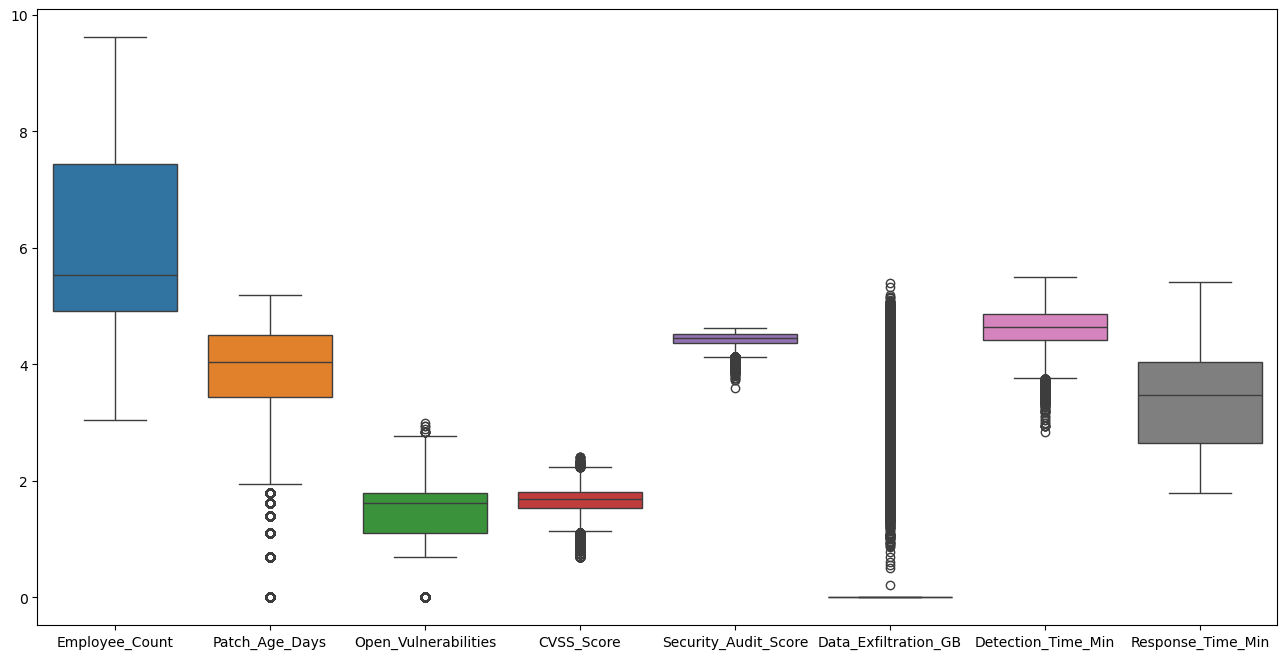

In [25]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['Employee_Count', 'Patch_Age_Days', 'Open_Vulnerabilities', 'CVSS_Score', 'Security_Audit_Score', 'Data_Exfiltration_GB',
        'Detection_Time_Min', 'Response_Time_Min']

plt.figure(figsize=(16,8))
sns.boxplot(data=np.log1p(df[cols]))
plt.show()

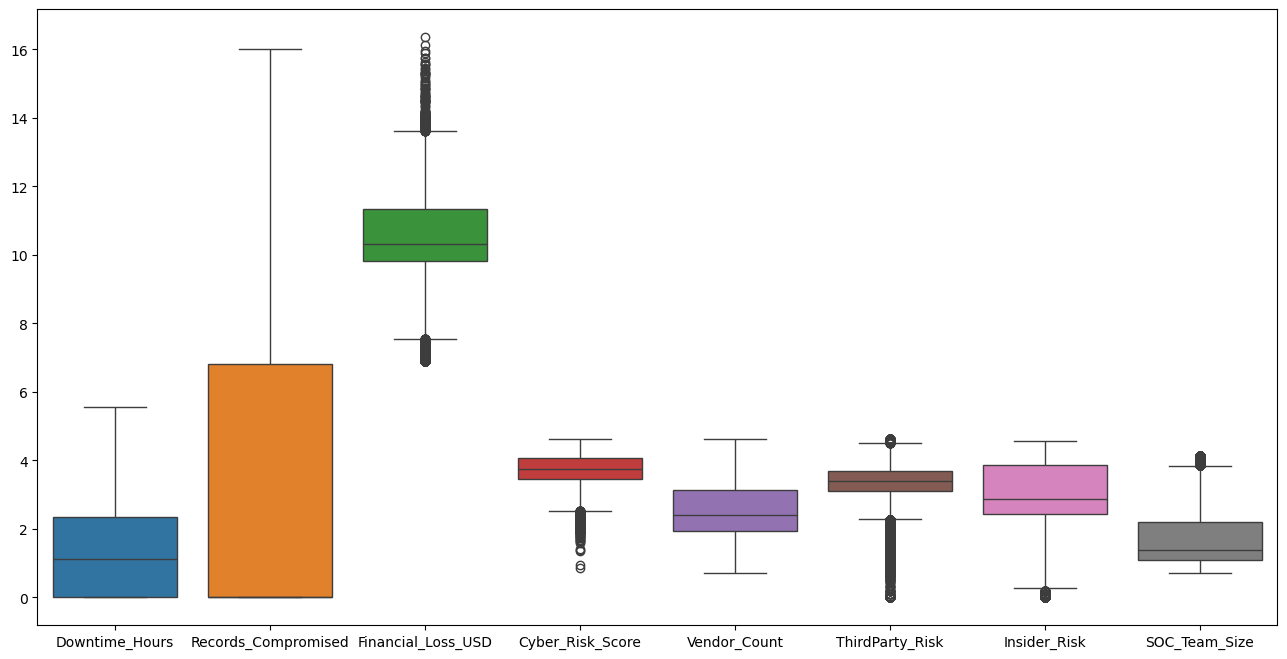

In [6]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['Downtime_Hours', 'Records_Compromised','Financial_Loss_USD', 'Cyber_Risk_Score',
      'Vendor_Count', 'ThirdParty_Risk', 'Insider_Risk', 'SOC_Team_Size']

plt.figure(figsize=(16,8))
sns.boxplot(data=np.log1p(df[cols]))
plt.show()

In [22]:

x = df.drop("Cyber_Risk_Score",axis =1)   #spliting x and y like other column and target column


y = df["Cyber_Risk_Score"]

In [23]:
from sklearn.model_selection import train_test_split


In [24]:
# spliting train and test data and also traget column and other columns
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [25]:
#scaling for improve accuracy and treat each column fairly because if some column 
#have high values the mechine gives important and gives priority to that column
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()  


In [26]:
x_train_scaler = scaler.fit_transform(x_train)   #  the scaling need to fit in train and transfrom and its takes all arrays
x_test_scaler = scaler.transform(x_test)        # its already fits in training data so jzt need  to transform


In [28]:
from sklearn.linear_model import LinearRegression    # using Regression model to train and test data
model = LinearRegression()
model.fit(x_train_scaler,y_train) 

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
from sklearn.metrics import (r2_score,mean_absolute_error,mean_squared_error)

y_pred = model.predict(x_train_scaler)  
y_t = model.predict(x_test_scaler)

print("R2 Score :",r2_score(y_train,y_pred))
print("MAE      :", mean_absolute_error(y_train, y_pred))
print("MSE      :", mean_squared_error(y_train, y_pred))
print("RMSE     :", mean_squared_error(y_train, y_pred)**0.5)
print("=======================================================")
print("R2 Score :",r2_score(y_test,y_t))
print("MAE      :", mean_absolute_error(y_test, y_t))
print("MSE      :", mean_squared_error(y_test, y_t))
print("RMSE     :", mean_squared_error(y_test, y_t)**0.5)

R2 Score : 0.96669347843474
MAE      : 2.558393374412624
MSE      : 12.050734784109958
RMSE     : 3.471416826615605
R2 Score : 0.9664358031752079
MAE      : 2.5789648169033885
MSE      : 12.311677175140684
RMSE     : 3.508799962257849


In [30]:
from sklearn.tree import DecisionTreeRegressor

model2 = DecisionTreeRegressor(max_depth=10,min_samples_split=10,min_samples_leaf=5,random_state=42)

model2.fit(x_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,10
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [31]:
from sklearn.metrics import (r2_score,mean_absolute_error,mean_squared_error)

y_pred2 = model2.predict(x_train)  
y_t2 = model2.predict(x_test)

print("R2 Score :",r2_score(y_train,y_pred2))
print("MAE      :", mean_absolute_error(y_train, y_pred2))
print("MSE      :", mean_squared_error(y_train, y_pred2))
print("RMSE     :", mean_squared_error(y_train, y_pred2)**0.5)
print("=======================================================")
print("R2 Score :",r2_score(y_test,y_t2))
print("MAE      :", mean_absolute_error(y_test, y_t2))
print("MSE      :", mean_squared_error(y_test, y_t2))
print("RMSE     :", mean_squared_error(y_test, y_t2)**0.5)

R2 Score : 0.9667353647041788
MAE      : 2.5678013684937024
MSE      : 12.035579784416784
RMSE     : 3.4692333136323916
R2 Score : 0.9631492471794354
MAE      : 2.7163905152140964
MSE      : 13.517218205935915
RMSE     : 3.6765769685858496


In [32]:
from sklearn.ensemble import RandomForestRegressor
model3 = RandomForestRegressor()
model3.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
y_pred3 = model3.predict(x_train)  
y_t3 = model3.predict(x_test)

print("R2 Score :",r2_score(y_train,y_pred3))
print("MAE      :", mean_absolute_error(y_train, y_pred3))
print("MSE      :", mean_squared_error(y_train, y_pred3))
print("RMSE     :", mean_squared_error(y_train, y_pred3)**0.5)
print("=======================================================")
print("R2 Score :",r2_score(y_test,y_t3))
print("MAE      :", mean_absolute_error(y_test, y_t3))
print("MSE      :", mean_squared_error(y_test, y_t3))
print("RMSE     :", mean_squared_error(y_test, y_t3)**0.5)

R2 Score : 0.99747880011426
MAE      : 0.7198563321254435
MSE      : 0.9122030681363591
RMSE     : 0.9550932248405697
R2 Score : 0.9823525810088654
MAE      : 1.9361506445653267
MSE      : 6.473246677924725
RMSE     : 2.5442575887525076


In [34]:
from sklearn.neighbors import KNeighborsRegressor
model4 = KNeighborsRegressor()
model4.fit(x_train_scaler,y_train) 

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [35]:
y_pred4 = model4.predict(x_train_scaler)  
y_t4 = model4.predict(x_test_scaler)

print("R2 Score :",r2_score(y_train,y_pred4))
print("MAE      :", mean_absolute_error(y_train, y_pred4))
print("MSE      :", mean_squared_error(y_train, y_pred4))
print("RMSE     :", mean_squared_error(y_train, y_pred4)**0.5)
print("=======================================================")
print("R2 Score :",r2_score(y_test,y_t4))
print("MAE      :", mean_absolute_error(y_test, y_t4))
print("MSE      :", mean_squared_error(y_test, y_t4))
print("RMSE     :", mean_squared_error(y_test, y_t4)**0.5)

R2 Score : 0.9414742255481549
MAE      : 3.5462864238735223
MSE      : 21.1753900680357
RMSE     : 4.601672529421851
R2 Score : 0.9134697390227405
MAE      : 4.335947983930686
MSE      : 31.740149916109065
RMSE     : 5.633839713384564


In [36]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Models and data used
models = [
    ("Linear Regression", model,
     x_train_scaler, x_test_scaler, "Scaled"),

    ("Decision Tree Regressor", model2,
     x_train, x_test, "Unscaled"),

    ("Random Forest Regressor", model3,
     x_train, x_test, "Unscaled"),

    ("K-Nearest Neighbors Regressor", model4,
     x_train_scaler, x_test_scaler, "Scaled"),
]

# Model characteristics
bias_variance = {
    "Linear Regression": "Higher bias, lower variance",
    "Decision Tree Regressor": "Low bias, high variance",
    "Random Forest Regressor": "Low bias, low variance",
    "K-Nearest Neighbors Regressor": "Flexible, high variance"
}

short_reason = {
    "Linear Regression": "Straight-line relationship",
    "Decision Tree Regressor": "Nonlinear decision rules",
    "Random Forest Regressor": "Ensemble of trees",
    "K-Nearest Neighbors Regressor": "Nearest neighbor prediction"
}

# Rules
OVERFIT_R2_GAP = 0.10
UNDERFIT_R2_THRESHOLD = 0.50

rows = []

for name, estimator, X_train_used, X_test_used, scaling in models:

    train_pred = estimator.predict(X_train_used)
    test_pred = estimator.predict(X_test_used)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    r2_gap = train_r2 - test_r2

    test_mae = mean_absolute_error(y_test, test_pred)
    test_mse = mean_squared_error(y_test, test_pred)
    test_rmse = np.sqrt(test_mse)

    overfit = "Yes" if r2_gap >= OVERFIT_R2_GAP else "No"

    underfit = (
        "Yes"
        if train_r2 < UNDERFIT_R2_THRESHOLD
        and test_r2 < UNDERFIT_R2_THRESHOLD
        else "No"
    )

    rows.append({
        "Model": name,
        "Data Used": scaling,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "R² Gap": r2_gap,
        "Test MAE": test_mae,
        "Test MSE": test_mse,
        "Test RMSE": test_rmse,
        "Overfit?": overfit,
        "Underfit?": underfit,
        "Bias / Variance": bias_variance[name],
        "Reason": short_reason[name]
    })

# Create comparison table
comparison = pd.DataFrame(rows)

comparison = comparison.sort_values(
    by="Test R²",
    ascending=False
).reset_index(drop=True)

comparison.insert(
    0,
    "Rank",
    range(1, len(comparison) + 1)
)

print("=" * 100)
print("REGRESSION MODEL COMPARISON")
print("=" * 100)

display(
    comparison.round({
        "Train R²": 4,
        "Test R²": 4,
        "R² Gap": 4,
        "Test MAE": 4,
        "Test MSE": 4,
        "Test RMSE": 4
    })
)

# Best model
best_model = comparison.iloc[0]

print("\n" + "=" * 100)
print("FINAL PROJECT RESULT")
print("=" * 100)

print(f"Best Model : {best_model['Model']}")
print(f"Test R²    : {best_model['Test R²']:.4f}")
print(f"Test MAE   : {best_model['Test MAE']:.4f}")
print(f"Test MSE   : {best_model['Test MSE']:.4f}")
print(f"Test RMSE  : {best_model['Test RMSE']:.4f}")

REGRESSION MODEL COMPARISON


,Rank,Model,Data Used,Train R²,Test R²,R² Gap,Test MAE,Test MSE,Test RMSE,Overfit?,Underfit?,Bias / Variance,Reason
0,1,Random Forest Regressor,Unscaled,0.9975,0.9824,0.0151,1.9362,6.4732,2.5443,No,No,"Low bias, low variance",Ensemble of trees
1,2,Linear Regression,Scaled,0.9667,0.9664,0.0003,2.5790,12.3117,3.5088,No,No,"Higher bias, lower variance",Straight-line relationship
2,3,Decision Tree Regressor,Unscaled,0.9667,0.9631,0.0036,2.7164,13.5172,3.6766,No,No,"Low bias, high variance",Nonlinear decision rules
3,4,K-Nearest Neighbors Regressor,Scaled,0.9415,0.9135,0.0280,4.3359,31.7401,5.6338,No,No,"Flexible, high variance",Nearest neighbor prediction



FINAL PROJECT RESULT
Best Model : Random Forest Regressor
Test R²    : 0.9824
Test MAE   : 1.9362
Test MSE   : 6.4732
Test RMSE  : 2.5443
